<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/AI_ExperimentalPhysics/FourierFiltering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The code in this notebook exemplifies the possibility to apply a short pass filter to a sound signal.

The signal is built as the sum of a low frequemcy harmonic, a high frequeuncy harmonic and a noise (random) term.

The the signal is filtered with a Butterworth fitler ( *from scipy.signal import butter, filtfilt*).
A Butterworth filter is a type of signal processing filter designed to have a frequency response that is as flat as possible in the passband (the range of frequencies it lets through).

Maximally Flat Passband: Unlike other filters (such as Chebyshev filters), a Butterworth filter introduces no ripples or distortion to the amplitudes of the frequencies you want to keep. **Frequencies below the cutoff remain virtually untouched until they get very close to the cutoff point.**

**Smooth Roll-off:** After the cutoff frequency, the signal's amplitude gradually drops toward zero rather than cutting off like a brick wall.

**Filter Order (order parameter):** Controls how steep that drop-off is. A higher order (e.g., order=6) creates a much sharper drop past the cutoff frequency than a lower order (e.g., order=1 or 2).

In the Python script, two functions from scipy.signal work together:

**butter**(order, normal_cutoff, btype='low'): Designs the filter and returns its mathematical coefficients (b and a), which define the transfer function. (It can also create 'high', 'bandpass', or 'bandstop' filters by changing btype).

**filtfilt**(b, a, data): Takes those b and a coefficients and actually applies the filter to your audio array.



**NOTE ABOUT THE CHOICE OF TIMES AND FREQUENCIES.**
fs = 44100  # Sampling rate (44.1 kHz)

duration = 3.0  # Seconds

t = np.linspace(0, duration, int(fs * duration), endpoint=False)

therefore every fs components along the signal vector , it is 1 s.
This is way in the *apply_lowpass_filter* routine the frequency of cutoff is given by

normal_cutoff = cutoff / nyquist

The variuable nyquist is 0.5*fs which is the unit of frequency given by the nyquist theorem : deltaf = 1/(0.5*fs), where df is interpreted as the total number of points in the time signal.

Low or High pass filter? [l/h]h
flag= h
high pass filtering
Original Sound (300 Hz + 3550 Hz):


Filtered Sound (Low-pass cutoff at 500.0 Hz):


Random level : 0.25


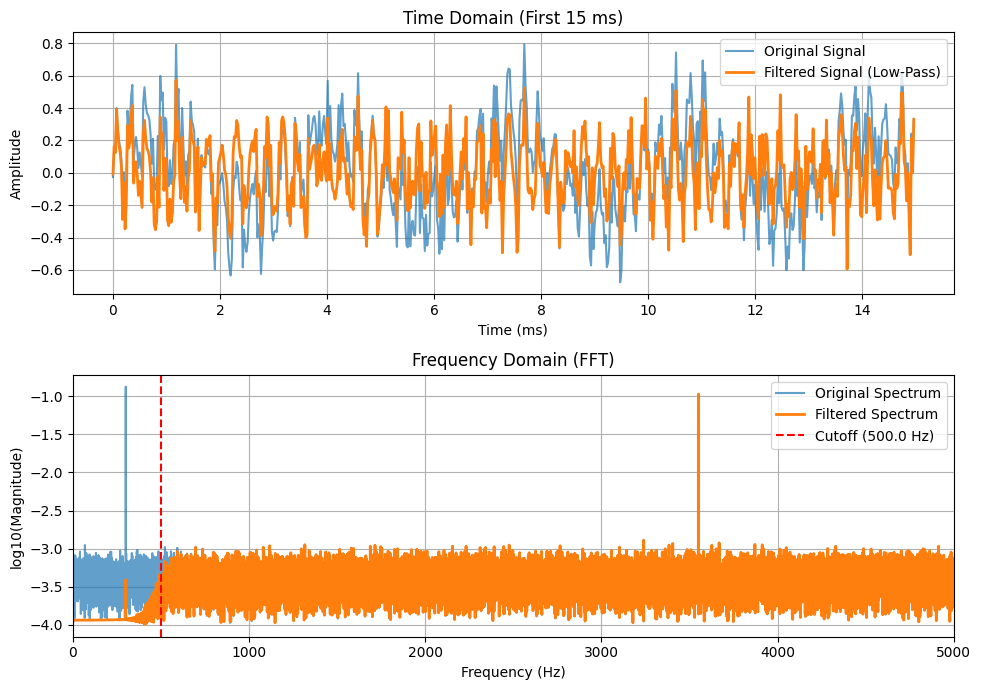

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from IPython.display import Audio, display

# ---------------------------------------------------------
# Generate an Audio Signal
# ---------------------------------------------------------
fs = 44100  # Sampling rate (44.1 kHz)
duration = 3.0  # Seconds
t = np.linspace(0, duration, int(fs * duration), endpoint=False)
######### notice that the vector of the signal corresponds to 1/fs time step
# Low-frequency tone (300 Hz) + high-frequency whistle (3500 Hz) + slight noise

f00 = 300 ## Hz
f01 = 3550 ## Hz
randomnoise_level = 0.25
low_tone = 0.5 * np.sin(2 * np.pi * f00 * t)
high_tone = 0.4 * np.sin(2 * np.pi * f01 * t)
noise = randomnoise_level * np.random.normal(0, 1, len(t))

original_signal = low_tone + high_tone + noise
original_signal = original_signal / np.max(np.abs(original_signal))  # Normalize

flagPass = 'l'
flagPass = input('Low or High pass filter? [l/h]')

# ---------------------------------------------------------
# Design and Apply the Low-Pass Filter
# ---------------------------------------------------------
def apply_lowpass_filter(data, cutoff, fs, order, flag):
    print ('flag=',flag)
    if flag == 'l' or flag == 'L':
      print ('low pass filtering')
      flag = 'low'
    elif flag == 'h' or flag == 'H':
      print ('high pass filtering')
      flag = 'high'

    nyquist = 0.5 * fs ## this is the maximal Nyquist frequency
    normal_cutoff = cutoff / nyquist #### this is the cutoff in pixels in the signal vector
    b, a = butter(order, normal_cutoff, btype=flag, analog=False)
    return filtfilt(b, a, data)

cutoff_freq = 500.0  # Cutoff frequency in Hz
filtered_signal = apply_lowpass_filter(original_signal, cutoff_freq, fs, 6,flagPass)

# ---------------------------------------------------------
# Display Audio Players in the Notebook
# ---------------------------------------------------------
print("Original Sound ("+str(f00)+" Hz + "+str(f01) +" Hz):")
display(Audio(original_signal, rate=fs))

print(f"Filtered Sound (Low-pass cutoff at {cutoff_freq} Hz):")
display(Audio(filtered_signal, rate=fs))
print(f"Random level :",randomnoise_level)

# ---------------------------------------------------------
# Plot Time Domain and Frequency Spectrum
# ---------------------------------------------------------
fig, axs = plt.subplots(2, 1, figsize=(10, 7))

# Time-domain plot (first 15 ms)
zoom_samples = int(0.015 * fs)
axs[0].plot(t[:zoom_samples] * 1000, original_signal[:zoom_samples], label='Original Signal', alpha=0.7)
axs[0].plot(t[:zoom_samples] * 1000, filtered_signal[:zoom_samples], label='Filtered Signal (Low-Pass)', linewidth=2)
axs[0].set_title('Time Domain (First 15 ms)')
axs[0].set_xlabel('Time (ms)')
axs[0].set_ylabel('Amplitude')
axs[0].legend()
axs[0].grid(True)

# Frequency-domain plot (FFT)
N = len(original_signal)
freqs = np.fft.rfftfreq(N, 1/fs)
orig_fft = np.abs(np.fft.rfft(original_signal)) / N
filt_fft = np.abs(np.fft.rfft(filtered_signal)) / N

axs[1].plot(freqs, np.log10(orig_fft+0.0001), label='Original Spectrum', alpha=0.7)
axs[1].plot(freqs, np.log10(filt_fft+0.0001), label='Filtered Spectrum', linewidth=2)
axs[1].axvline(cutoff_freq, color='r', linestyle='--', label=f'Cutoff ({cutoff_freq} Hz)')
axs[1].set_title('Frequency Domain (FFT)')
axs[1].set_xlabel('Frequency (Hz)')
axs[1].set_ylabel('log10(Magnitude)')
axs[1].set_xlim(0, 5000)
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()